### Problem 21 : RAG and vector stores - deleting every copy

⏱️ ~45 min · 🧭 Stage 8 (Extensions) · 📄 Lewis et al. 2020 (RAG), Zeng et al. 2024 (privacy in RAG), `resources/papers/04-evaluation-and-privacy/2023-morris-text-embeddings-reveal-text.pdf`, `resources/papers/04-evaluation-and-privacy/2019-carlini-secret-sharer-canary-exposure.pdf`

> 🔗 **Building on Problems 1, 16 and 17 :** in Problem 1 the model *was* the data (k-NN), so forgetting was deleting
> rows. In Problem 16 a phone number was learned into a language model's weights, and it was hard to remove. Many
> chatbots today sit between the two. The language model does not learn the company's documents. It **looks them
> up** at answer time and reads the best matches before it answers. This is **retrieval-augmented generation**, or
> RAG (Lewis et al. 2020). Is forgetting then as easy as in Problem 1? Problem 17's lineage registry will matter here.

Kestrel Home (a fictional online shop for kitchen appliances) runs a support chatbot. When a customer asks a
question, the chatbot searches the old support tickets and answers from the best matches. **Fiona Kowalczyk** wrote
four tickets last winter. They hold her phone number, her address, the last digits of her card and the fact that she
was in hospital for an operation. Health data is a special category of personal data (GDPR Art. 9). Fiona closes her
account and asks Kestrel Home to erase all her tickets (GDPR Art. 17).

> 🟢 **In plain words :** think of a help desk with a filing cabinet of old letters. To answer quickly, the staff have
> photocopied the useful paragraphs into a binder, written an index card for every important word, kept a notebook of
> answers they gave, and written a diary of every call. Throwing Fiona's letters out of the cabinet leaves her words in
> the binder, on the index cards, in the notebook and in the diary. Forgetting her means finding every copy.

> 🔴 **For practitioners :** in RAG, the person's data sits in **stores**, not in weights. Deleting from a store is
> exact unlearning, rung 1 of the Ladder (Problem 1). The work is in finding every copy. That means the chunks, the
> embeddings, the keyword index, the answer cache, the logs and the backups, and indexes that only **mark** a row as
> deleted until they are compacted. Embeddings are not anonymous (Morris et al. 2023 rebuilt most short texts from
> neural embeddings). RAG systems can be pushed into repeating the text they retrieve (Zeng et al. 2024), so a
> leftover copy is a real leak. And if any model was **trained** on the tickets, it is a weights problem again.

**TASK :** Build a small RAG stack in NumPy. Delete Fiona the naive way and count the copies that are left. Delete her
by owner ID from every store, catch the tombstone trap and compact. Prove that the result is the stack built without
her, then find the one place where deleting from the stores is not enough.

In [1]:
# On Google Colab? Run this cell first : it fetches the course library (mul/) and the diagrams. Locally it does nothing.
import os, sys
if "google.colab" in sys.modules and not os.path.isdir("mul"):
    !git clone -q --depth 1 https://github.com/Shreyan1/machine-unlearning-course.git
    %cd machine-unlearning-course

In [2]:
import copy, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mul import rag, lm, viz
viz.style()
START = time.perf_counter()

FIONA = "C-FIONA"                                   # her customer ID. Every copy of her data should carry it
tickets = rag.make_tickets(seed=0)                  # the ticket database (all fictional)
hers = [t for t in tickets if t["owner"] == FIONA]
others = [t for t in tickets if t["owner"] != FIONA]

print(f"{len(tickets)} tickets from {len({t['owner'] for t in tickets})} customers. {len(hers)} of them are Fiona's.\n")
print("A typical ticket:\n ", others[0]["text"], "\n")
print("Fiona's first ticket:\n ", hers[0]["text"])

230 tickets from 81 customers. 4 of them are Fiona's.

A typical ticket:
  hi, the kettle i bought (order 53567) has not arrived yet. elif khan, tel 555-0139. agent: sorry about this, elif. we have asked the courier to call you. 

Fiona's first ticket:
  hello, my air fryer from order 50417 arrived broken. i am in hospital for an operation until 3 march, so please do not send anything to 14 larch row before then. fiona kowalczyk, tel 555-0147. agent: sorry to hear that, fiona. we have paused the replacement for order 50417 until 4 march.


`rag.make_tickets` writes the tickets from a few templates (`mul/rag.py`). Each one is a customer's message followed by
the support agent's reply. All phone numbers are in 555-0100 to 555-0199, the range kept for fiction, and nobody else
has Fiona's number.

#### Step 1 : Train - build the retrieval stack

Nothing here is trained by gradient descent. "Training" a RAG system means building its stores. Each piece is a few
lines in `mul/rag.py`.

1. **Chunks** (`rag.chunk`). Each ticket is cut into windows of 24 words that overlap by 8 words. Search works on
   chunks, not whole documents, so a long document can match on one paragraph. The chunks are stored on their own.
2. **Embeddings** (`rag.HashEmbedder`). An embedding is a list of numbers that stands for a text. Ours is a
   *hashed bag of words*. Every word is sent by a fixed hash function to one of 4,000 slots, with a + or - sign, and
   the vector is scaled to length 1. Two chunks that share many words get a high **cosine similarity** (the dot product
   of two length-1 vectors). Real systems use a neural embedder, which also captures meaning. Both are fixed once
   built, so a chunk's vector depends only on its own text.
3. **Vector index** (`rag.VectorIndex`). One row per chunk. A search returns the rows with the highest cosine to the
   question. This is the nearest-neighbour search of Problem 1.
4. **Keyword index** (`rag.KeywordIndex`). For every word, the list of chunks that contain it and how often. Search
   uses **BM25** (Robertson & Zaragoza 2009), the standard keyword score : a chunk scores higher when it contains the
   question's words, and rare words count more than common ones.
5. **Hybrid search**. The two result lists are merged by *reciprocal rank fusion* (Cormack et al. 2009) : each chunk
   gets `1 / (60 + rank)` from each list, and the top 3 go to the answerer.
6. **The answerer** (`rag.answer`). A real chatbot passes the 3 chunks to a language model. Ours stands in for it by
   copying the sentence that shares the most words with the question. Real models also copy names and numbers from
   what they read, which is why this is a fair stand-in for a privacy test.

In [3]:
# Step 1a: build the stores from the ticket database
emb = rag.HashEmbedder(dim=4000)

def build(rows):
    # The chatbot's stores for a list of tickets: chunks, vectors and keywords, with an empty cache and empty logs
    return rag.RAGStack(emb, size=24, overlap=8, k=3, cache_threshold=0.8).add_tickets(rows)

t0 = time.perf_counter()
bot = build(tickets)
build_seconds = time.perf_counter() - t0
first_chunk = next(iter(bot.chunks))
print(f"built in {build_seconds:.2f} s")
print(f"ticket database : {len(bot.tickets)} tickets")
print(f"chunk store     : {len(bot.chunks)} chunks, e.g. {first_chunk} = {bot.chunks[first_chunk]['text']!r}")
print(f"vector index    : {bot.vectors.V.shape[0]} rows x {bot.vectors.V.shape[1]} numbers")
print(f"keyword index   : {len(bot.keywords.postings)} different words")

q = "fiona here, what is happening with my air fryer?"
print(f"\nQ: {q}")
for cid in bot.retrieve(q):
    print(f"   retrieved {cid:8s} (owner {bot.chunks[cid]['owner']}) {bot.chunks[cid]['text']!r}")
print("A:", bot.ask(FIONA, q, record=False))

built in 0.01 s
ticket database : 230 tickets
chunk store     : 440 chunks, e.g. T0000/0 = 'hi, the kettle i bought (order 53567) has not arrived yet. elif khan, tel 555-0139. agent: sorry about this, elif. we have asked the'
vector index    : 440 rows x 4000 numbers
keyword index   : 527 different words

Q: fiona here, what is happening with my air fryer?
   retrieved T0075/0  (owner C-000) 'hello, my air fryer from order 58926 was charged to my card twice. this is the second time this has happened. kenji evans, tel'
   retrieved T0032/0  (owner C-FIONA) 'order 50417. the air fryer was charged to my card twice. please refund the second payment to my card ending 7731. fiona kowalczyk, tel'
   retrieved T0176/0  (owner C-032) 'order 53147. my new air fryer was charged to my card twice. this is the second time this has happened. dev brown, tel 555-0134.'
A: hello, my air fryer from order 58926 was charged to my card twice.


Every chunk ID is `ticket/number`, and every chunk, vector and keyword entry carries its **owner**, the customer it
came from. This tag is Problem 17's lineage. Without it, a deletion has no way to find the copies.

How good is the search for everyone else? Each other customer asks about one of their own tickets, in a short
question that names only their first name and the product. We count how often their ticket is among the 3 chunks
retrieved (**hit@3**). We will check that this number does not suffer when Fiona is deleted.

In [4]:
# Step 1b: search quality for everyone else
question = lambda t: f"{t['first']} here, what is happening with my {t['product']}?"

def found(stack):
    # For each other customer's ticket: is one of its chunks in the top 3 for that customer's question?
    return np.array([any(c.startswith(t["ticket"] + "/") for c in stack.retrieve(question(t))) for t in others])

before = found(bot)
chance = np.mean([sum(c.startswith(t["ticket"] + "/") for c in bot.chunks) for t in others]) * 3 / len(bot.chunks)
print(f"{len(others)} questions, e.g. {question(others[0])!r}")
print(f"hit@3 : {before.mean():.1%}   (3 chunks picked at random would hit about {chance:.1%})")

226 questions, e.g. 'elif here, what is happening with my kettle?'
hit@3 : 74.8%   (3 chunks picked at random would hit about 1.3%)


The search is far better than chance but not perfect, because several customers share a first name and a product.
That is fine. What matters is that the number is a fair check for everyone who is **not** Fiona.

Now a month of use. Customers ask about their orders. Fiona asks one question herself, a support agent looks her up,
and her neighbour asks about a parcel. Every question is answered, the answer is **cached** (kept, so that a similar
question later gets the same answer without a new search), and the whole exchange is **logged**.

In [5]:
# Step 1c: a month of questions. Each one is answered, cached and logged
rng = np.random.default_rng(1)
neighbour = next(t for t in others if "neighbour" in t["text"])      # the customer who lives next door to Fiona
traffic = [(others[i]["owner"], f"{others[i]['first']} {others[i]['last']} order {others[i]['order']} status")
           for i in rng.choice(len(others), 60, replace=False)]
traffic[10:10] = [(FIONA, "is my air fryer paused while i am in hospital?")]
traffic[25:25] = [("agent-3", "fiona kowalczyk phone number")]
traffic[40:40] = [(neighbour["owner"], "where is my toaster? it was left with my neighbour")]
for asker, q in traffic:
    bot.ask(asker, q)

print(f"{len(traffic)} questions -> {len(bot.cache.entries)} cached answers and {len(bot.logs)} log records\n")
for r in bot.logs:
    if r["asker"] in (FIONA, "agent-3"):
        print(f"{r['asker']:8s} asked {r['query']!r}\n         and got {r['answer']!r}")

63 questions -> 63 cached answers and 63 log records

C-FIONA  asked 'is my air fryer paused while i am in hospital?'
         and got 'collecting post at 14 larch row while i am in hospital.'
agent-3  asked 'fiona kowalczyk phone number'
         and got 'fiona kowalczyk, tel 555-0147.'


#### Step 2 : Show the issue - deleting the tickets is not deleting Fiona

The usual first answer to "erase my tickets" is to delete them from the ticket database. We do exactly that on a copy
of the chatbot, and nothing else. `copies(owner)` counts the items in each store that carry Fiona's ID.

In [6]:
# Step 2a: delete her tickets from the ticket database, and nothing else
naive = copy.deepcopy(bot)
for t in hers:
    del naive.tickets[t["ticket"]]
print(pd.DataFrame({"before": bot.copies(FIONA), "after deleting her tickets": naive.copies(FIONA)}).to_string())

PROBES = ["phone number for fiona kowalczyk please", "who lives at 14 larch row?",
          "which customer is in hospital for an operation?", "refund to the card ending 7731"]

def probe(stack):
    # Ask each probe question without caching or logging it, and say when the answer came from the cache
    for q in PROBES:
        a = stack.ask("stranger", q, record=False)
        print(f"  {q!r:52s} -> {a!r}{'   (from the cache)' if stack.last_from_cache else ''}")

print("\nA stranger asks the chatbot:")
probe(naive)

                 before  after deleting her tickets
ticket database       4                           0
chunk store          10                          10
vector index         10                          10
keyword index        10                          10
answer cache          2                           2
logs                  2                           2

A stranger asks the chatbot:
  'phone number for fiona kowalczyk please'            -> 'fiona kowalczyk, tel 555-0147.'   (from the cache)
  'who lives at 14 larch row?'                         -> 'my daughter mila is collecting post at 14 larch row while i'
  'which customer is in hospital for an operation?'    -> 'i am in hospital for an operation until 3 march, so please do not send'
  'refund to the card ending 7731'                     -> 'please refund the second payment to my card ending 7731.'


The ticket database is clean, and the chatbot still gives out her phone number, her address, her hospital stay and her
card digits. Each answer comes from a different copy. The phone number came straight from the **cache** : the
question is close enough to the agent's earlier one ("fiona kowalczyk phone number") that the old answer was served
again. The others came from the **chunks**, found through the vector and keyword indexes. And the logs still hold
the agent's question and Fiona's own question about her hospital stay.

A note on our own test questions. We ask them with `record=False`, so they are not cached or logged. A real chatbot
would cache and log them too, and every one of them contains Fiona's name. Run deletion checks against a copy, or
with logging switched off.

##### Step 2b : Embeddings are not anonymous

A common hope is that the vectors are safe to keep, because they are "just numbers". Let us test that. In a hashed
embedding every word lands in a fixed slot with a fixed sign. A slot is non-zero only if some word of the chunk landed
there. So an attacker who holds a stored vector takes a list of words and keeps every word whose slot is non-zero with
the right sign. Our attacker's list is every word in the *other* customers' tickets (the language of support tickets)
plus public lists of names and streets, like a phone book or a map.

In [7]:
# Step 2b: read her words back out of her stored vectors
public = sorted({w for t in others for w in rag.tokens(t["text"]) if not w.isdigit()}
                | set(rag.FIRST_NAMES) | set(rag.SURNAMES) | {w for s in rag.STREETS for w in s.split()})
rows = [i for i, o in enumerate(naive.vectors.owners) if o == FIONA]
true_words, got_words, wrong = set(), set(), 0
for i in rows:
    truth = {w for w in rag.tokens(bot.chunks[naive.vectors.ids[i]]["text"]) if not w.isdigit()}
    guess = set(rag.invert(emb, naive.vectors.V[i], public))
    true_words |= truth; got_words |= guess & truth; wrong += len(guess - truth)

i = rows[0]
print(f"the attacker's word list: {len(public)} words\n")
print("stored chunk :", bot.chunks[naive.vectors.ids[i]]["text"])
print("from vector  :", " ".join(rag.invert(emb, naive.vectors.V[i], public)), "\n")
print(f"over her {len(rows)} vectors: {len(got_words)} of her {len(true_words)} different words recovered, "
      f"{wrong} wrong guesses")
print("missed, because they are not in the list:", ", ".join(sorted(true_words - got_words)))

phones = [f"01{n:02d}" for n in range(100)]
fit = sorted({p for i in rows for p in rag.invert(emb, naive.vectors.V[i], phones)})
print(f"\nwhich of the 100 numbers 555-0100 ... 555-0199 fit her vectors? {['555-' + p for p in fit]}")

the attacker's word list: 165 words

stored chunk : hello, my air fryer from order 50417 arrived broken. i am in hospital for an operation until 3 march, so please do not send
from vector  : air arrived broken for from fryer hello hospital i in my not order 

over her 10 vectors: 56 of her 77 different words recovered, 0 wrong guesses
missed, because they are not in the list: am, an, anything, collecting, daughter, do, ending, hear, march, operation, paused, please, post, refund, send, so, thank, that, then, until, while

which of the 100 numbers 555-0100 ... 555-0199 fit her vectors? ['555-0147', '555-0196']


Across her ten vectors, the attack recovers 56 of her 77 different words, including her name, her street and the word
*hospital*, with no wrong guesses. The only words it missed are the ones that were not on the attacker's list, and a
bigger list (a full dictionary) would find those too. Trying all 100 possible phone numbers leaves just two that fit,
and one of them is hers. (The other one shares a slot with a word in her chunks, which is a *hash collision*.)

Hashed vectors are an easy case, because the hash is public. Neural embeddings are harder to read, but not safe :
Morris et al. (2023) trained a model that turns neural embeddings back into text, and it rebuilt most short texts word
for word. **Treat stored embeddings as copies of the text.**

#### Step 3 : Untrain - delete by owner ID from every store

`forget(owner)` uses the tags. It deletes every ticket, chunk, vector and keyword entry with her ID, every cached
answer that was built from her chunks or asked by her, and every log record that touched her.

In [8]:
# Step 3a: delete by owner ID from every store
clean = copy.deepcopy(bot)
print("removed:", clean.forget(FIONA))

mine = {c for c, v in bot.chunks.items() if v["owner"] == FIONA}          # her 10 chunk IDs
asked = PROBES + [question(t) for t in others]
returned = sum(len(mine & set(clean.retrieve(q, k=20))) for q in asked)
print(f"her chunks in the top 20 of {len(asked)} searches: {returned}")

removed: {'ticket database': 4, 'chunk store': 10, 'vector index': 10, 'keyword index': 10, 'answer cache': 2, 'logs': 2}
her chunks in the top 20 of 230 searches: 0


No search returns her chunks any more. That looks finished. But look at *how* the two indexes deleted her.

Most vector databases and search engines do not remove a row when you delete it. Removing a row from the middle of a
big file is slow, so they write a **tombstone** instead : a mark that says "skip this row". The row itself stays on
disk until a later clean-up called **compaction** (or a merge, or a rebuild) rewrites the file without it. Our
`VectorIndex` and `KeywordIndex` work the same way.

In [9]:
# Step 3a (continued): the tombstone trap
snap = clean.vectors.snapshot()                       # what tonight's backup of the index file would hold
dead = [j for j, alive in enumerate(snap["alive"]) if not alive]
j = snap["ids"].index(naive.vectors.ids[rows[0]])    # the same chunk as in Step 2b
after_forget = clean.copies(FIONA)
print(f"vector index : {len(snap['ids'])} rows stored, {snap['alive'].sum()} searchable, {len(dead)} tombstones")
print(f"   one tombstoned row, read back from the backup: {' '.join(rag.invert(emb, snap['V'][j], public))}")
live_df = sum("kowalczyk" in v["text"] for v in clean.chunks.values())
print(f"keyword index: 'kowalczyk' still counts as appearing in {clean.keywords.df('kowalczyk')} chunks "
      f"(searchable chunks that contain it: {live_df})")
print("\nitems still tagged with her ID:", after_forget)

vector index : 440 rows stored, 430 searchable, 10 tombstones
   one tombstoned row, read back from the backup: air arrived broken for from fryer hello hospital i in my not order
keyword index: 'kowalczyk' still counts as appearing in 8 chunks (searchable chunks that contain it: 2)

items still tagged with her ID: {'ticket database': 0, 'chunk store': 0, 'vector index': 10, 'keyword index': 10, 'answer cache': 0, 'logs': 0}


**The tombstone trap.** Her 10 vectors are still in memory and in every backup, and Step 2b's attack still reads them.
The keyword index still counts her chunks in its word statistics, so the score of the word "kowalczyk" is computed
as if she were still there. This is how Lucene-based search engines such as Elasticsearch behave until segments are
merged. A deletion is only finished when the tombstoned rows are physically gone.

vector index : 430 rows stored, 0 tombstones
keyword index: 'kowalczyk' counts as appearing in 2 chunks

items tagged with her ID, in each store:
                 before  delete her tickets only  forget(), tombstones  forget() + compact()
ticket database       4                        0                     0                     0
chunk store          10                       10                     0                     0
vector index         10                       10                    10                     0
keyword index        10                       10                    10                     0
answer cache          2                        2                     0                     0
logs                  2                        2                     0                     0


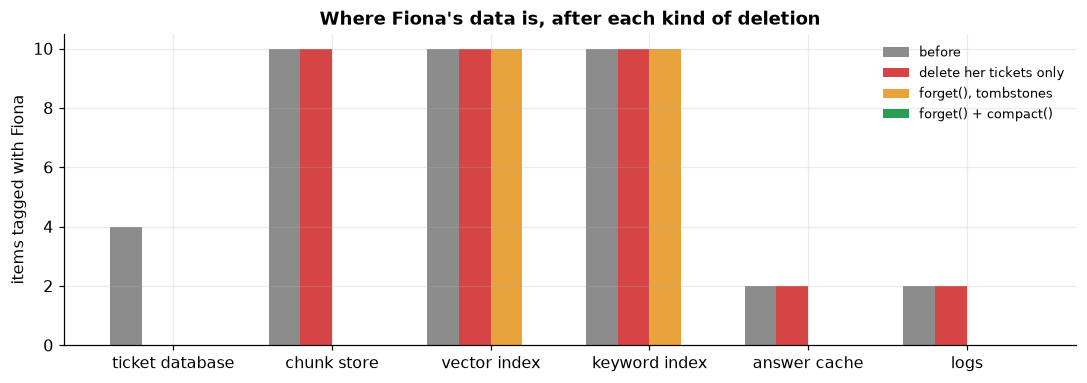

In [10]:
# Step 3b: compaction rewrites both indexes without the tombstoned rows
clean.compact()
snap = clean.vectors.snapshot()
print(f"vector index : {len(snap['ids'])} rows stored, {int((~snap['alive']).sum())} tombstones")
print(f"keyword index: 'kowalczyk' counts as appearing in {clean.keywords.df('kowalczyk')} chunks")

stages = pd.DataFrame({"before": bot.copies(FIONA), "delete her tickets only": naive.copies(FIONA),
                       "forget(), tombstones": after_forget, "forget() + compact()": clean.copies(FIONA)})
print("\nitems tagged with her ID, in each store:\n" + stages.to_string())

fig, ax = plt.subplots(figsize=(10, 3.6))
colors = [viz.ORIGINAL, viz.FORGET, viz.ACCENT, viz.RETRAIN]
x, w = np.arange(len(stages)), 0.2
for k, (name, c) in enumerate(zip(stages.columns, colors)):
    ax.bar(x + (k - 1.5) * w, stages[name], w, color=c, label=name)
ax.set_xticks(x, stages.index); ax.set_ylabel("items tagged with Fiona")
ax.set_title("Where Fiona's data is, after each kind of deletion"); ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

After compaction, no store holds anything tagged with her. Deleting her tickets alone emptied one store out of six.

##### Step 3c : An approximate index has a trained part

With millions of chunks, comparing a question with every row is too slow, so real systems use an **approximate
nearest-neighbour** (ANN) index. One common kind is the *inverted file* (IVF, as in Jégou et al. 2011). k-means
groups the vectors into lists, and each list has a **centroid**, the average of its vectors. A search compares the
question with the centroids and only looks inside the closest few lists. `rag.IVFIndex` does this with 16 lists.

The centroids are averages of the stored vectors, so they are a small **trained model** of the data, and Fiona is in
it. Deleting her rows from the lists does not change the centroids. We look at the centroids' weight in the slot of
her phone number's last four digits, "0147".

In [11]:
# Step 3c: the centroids of an IVF index keep a trace of deleted rows until the index is rebuilt
ivf = rag.IVFIndex(n_lists=16, seed=0).fit(bot.vectors.ids, bot.vectors.V)
qv = [emb([question(t)])[0] for t in others]
share = np.mean([len(set(ivf.search(v, 3, nprobe=4)) & set(bot.vectors.search(v, 3))) / 3 for v in qv])
print(f"IVF with 16 lists, searching the 4 closest: it finds {share:.0%} of the exact top 3")

slot, sign = emb.slot("0147")
weight = lambda index: float((index.centroids[:, slot] * sign).max())
print(f"largest centroid weight in the slot of '0147' : {weight(ivf):.4f}")
ivf.remove(mine)
print(f"after removing her {len(mine)} rows from the lists : {weight(ivf):.4f}   ({len(ivf.ids)} rows left)")
rebuilt = rag.IVFIndex(n_lists=16, seed=0).fit(clean.vectors.ids, clean.vectors.V)
print(f"after a rebuild on the rows that are left     : {weight(rebuilt):.4f}")

IVF with 16 lists, searching the 4 closest: it finds 75% of the exact top 3
largest centroid weight in the slot of '0147' : 0.1643
after removing her 10 rows from the lists : 0.1643   (430 rows left)
after a rebuild on the rows that are left     : 0.0000


The approximate index finds most, but not all, of the exact results. That is the usual price of speed. Removing her
rows from the lists leaves her phone number's slot in the centroids exactly as it was. Only a **rebuild**, which
retrains k-means on the rows that are left, clears it. Graph indexes such as HNSW have the same problem in another
form : a deleted node is often only marked, and it still helps route searches until the graph is rebuilt. **Plan an
index rebuild inside the deletion deadline, not just a delete call.**

#### Step 4 : Show the result

The same stranger asks the same questions of the cleaned and compacted chatbot.

In [12]:
# Step 4a: the probe questions again
print("After forget() + compact():")
probe(clean)

After forget() + compact():
  'phone number for fiona kowalczyk please'            -> 'the tracking says it was left with my neighbour fiona kowalczyk at 14 larch'
  'who lives at 14 larch row?'                         -> 'with my neighbour fiona kowalczyk at 14 larch row, but she is in hospital.'
  'which customer is in hospital for an operation?'    -> 'with my neighbour fiona kowalczyk at 14 larch row, but she is in hospital.'
  'refund to the card ending 7731'                     -> 'hi, the coffee machine i bought (order 41676) was charged to my card twice.'


Her own tickets are gone, and so are her phone number and her card digits. But the chatbot still says that Fiona
Kowalczyk lives at 14 Larch Row and is in hospital. That text is in her **neighbour's** ticket ("left with my
neighbour fiona kowalczyk at 14 larch row"). The ticket belongs to the neighbour, so it carries the neighbour's ID,
and deleting by Fiona's ID never touched it.

**Tags find what came from a person, not what is about them.** So the last check must not rely on the tags. We
search every store's raw contents for her identifiers (`scan`) : the text stores directly, the keyword index by its
words, and the vector index with Step 2b's attack.

In [13]:
# Step 4b: search every store for her identifiers, without using the tags
NEEDLES = ["kowalczyk", "555-0147", "larch row", "7731"]
found_before = clean.scan(NEEDLES)
for c, v in clean.chunks.items():
    if any(n in v["text"] for n in NEEDLES):
        print(f"{c} (owner {v['owner']}): {v['text']!r}")

MENTION = "my neighbour fiona kowalczyk at 14 larch row, but she is in hospital"
clean.redact(neighbour["ticket"], MENTION, "my neighbour [removed]")   # remove her details, keep the neighbour's ticket
clean.compact()
print("\n" + pd.DataFrame({"after forget() + compact()": found_before, "after also redacting the mention": clean.scan(NEEDLES)}).to_string())
print("\nThe probe questions again:")
probe(clean)

T0169/0 (owner C-040): 'hi, my toaster from order 48569 has not arrived yet. the tracking says it was left with my neighbour fiona kowalczyk at 14 larch'
T0169/1 (owner C-040): 'with my neighbour fiona kowalczyk at 14 larch row, but she is in hospital. kavya bell, tel 555-0130. agent: sorry about this, kavya. we'

                 after forget() + compact()  after also redacting the mention
ticket database                           1                                 0
chunk store                               2                                 0
vector index                              2                                 0
keyword index                             2                                 0
answer cache                              1                                 0
logs                                      1                                 0

The probe questions again:
  'phone number for fiona kowalczyk please'            -> 'we have booked a collection for repair.'
  'who liv

The scan finds the neighbour's ticket in the database, its two chunks in both indexes, and the cached answer and log
record of the neighbour's own question, which quoted it. We **redact** the mention : her details are replaced by
"[removed]", and the neighbour's ticket stays, because it is the neighbour's data. `redact` drops the old chunks,
cached answers and log records built from that ticket and indexes the new text. Now the scan is clean, and no probe
question brings back anything about her.

Is the chatbot as good as before for everyone else?

In [14]:
# Step 4c: search quality for everyone else
after = found(clean)
print(f"hit@3 for the other customers : before {before.mean():.1%}, after {after.mean():.1%}")
print(f"questions whose hit changed   : {(before != after).sum()} of {len(others)} "
      f"({(~before & after).sum()} gained, {(before & ~after).sum()} lost)")

hit@3 for the other customers : before 74.8%, after 73.9%
questions whose hit changed   : 2 of 226 (0 gained, 2 lost)


Almost nothing changed. Two of the 226 questions no longer find their ticket in the top 3, and none gained. Removing
her chunks shifts the ranks in both result lists, and the keyword scores change a little because the word statistics
no longer include her. Is that loss a problem? That is not a matter of opinion. The right answer is whatever a stack that never held her data gives, and
that is the test in Step 5.

#### Step 5 : Prove it - against the stack built without her

For retrieval, the gold standard is simple and exact. Take the erased ticket database (everyone else's tickets, with
the neighbour's mention redacted) and build every store from scratch. After compaction, our cleaned stack should be
**identical** to it : the same tickets, the same chunks, the same vectors to the last bit, the same keyword counts
and the same search results. This is Problem 1's k-NN result, for a whole pipeline.

In [15]:
# Step 5a: compare every store with a stack built from scratch on the erased database
erased = [dict(t, text=t["text"].replace(MENTION, "my neighbour [removed]")) for t in others]
gold = build(erased)
ivf_of = lambda s: rag.IVFIndex(n_lists=16, seed=0).fit(s.vectors.ids, s.vectors.V)
checks = {"ticket database": clean.tickets == gold.tickets,
          "chunk store": clean.chunks == gold.chunks,
          "vector index (every number)": clean.vectors.same_as(gold.vectors),
          "keyword index (every count)": clean.keywords.same_as(gold.keywords),
          f"search results ({len(asked)} questions)": all(clean.retrieve(q) == gold.retrieve(q) for q in asked),
          "IVF centroids after a rebuild": np.array_equal(ivf_of(clean).centroids, ivf_of(gold).centroids),
          "hit@3 for the other customers": bool((found(clean) == found(gold)).all())}
for name, ok in checks.items():
    print(f"{'✅' if ok else '❌'} {name}")

print(f"\ncache and logs: {clean.copies(FIONA)['answer cache']} cached answers and {clean.copies(FIONA)['logs']} log "
      f"records tagged with her; {clean.scan(NEEDLES)['answer cache']} and {clean.scan(NEEDLES)['logs']} contain her details")
re_embedded = sum(c.startswith(neighbour["ticket"] + "/") for c in clean.chunks)
print(f"cost: {re_embedded} chunks embedded again (the neighbour's redacted ticket) vs {len(gold.chunks)} for a full rebuild")

✅ ticket database
✅ chunk store
✅ vector index (every number)
✅ keyword index (every count)
✅ search results (230 questions)
✅ IVF centroids after a rebuild
✅ hit@3 for the other customers

cache and logs: 0 cached answers and 0 log records tagged with her; 0 and 0 contain her details
cost: 2 chunks embedded again (the neighbour's redacted ticket) vs 429 for a full rebuild


Every store matches the stack built without her, bit for bit, and the two questions that lost their ticket in Step 4
lose it in the stack built without her too. Retrieval is **exact unlearning**, and it is cheap : the deletion
embedded two chunks again (the neighbour's redacted ticket), where a rebuild embeds all 429.

The cache and the logs are different. They are a *history* of past questions, and history cannot be rebuilt "as if
she had never been there", because other people's questions would have had other answers. For them the standard is
weaker but still checkable : no entry built from her data, and no entry that contains her details. Both hold.

##### Step 5b : The twist - a model trained on the tickets

Kestrel Home did one more thing with the tickets. To help its support staff, it trained a small text model on them
that suggests how to finish a reply. We use the n-gram language model from Problem 16 (`lm.NGramLM`), which predicts
the next character from the last 16. Nothing in Steps 3 and 4 touched it, because it is not a store. It is a model.

We measure it as in Problem 16 : does it complete "fiona kowalczyk, tel " with her number, and what is the
**exposure** of her number (Carlini et al. 2019) among the 100 possible numbers? The maximum, 6.64 bits, means "her
number is the model's top guess".

In [16]:
# Step 5b: the drafting model, trained on every ticket
lines = lambda rows: [t["text"] + "\n" for t in rows]
CANDIDATES = [f"555-01{n:02d}" for n in range(100)]

def check(m):
    exposure, rank = lm.exposure(m.seq_logprob, "fiona kowalczyk, tel ", "555-0147", CANDIDATES)
    return {"'fiona kowalczyk, tel ' ->": m.complete("fiona kowalczyk, tel ", 8),
            "'my neighbour fiona kowalczyk at ' ->": m.complete("my neighbour fiona kowalczyk at ", 13),
            "exposure (bits)": round(exposure, 2), "rank of her number": int(rank)}

drafter = lm.NGramLM(order=16).fit(lines(tickets))
results = {"trained on every ticket": check(drafter),
           "after Steps 3-4 (stores cleaned)": check(drafter)}
unlearned = copy.deepcopy(drafter).unlearn(lines(hers))
results["unlearn her 4 tickets"] = check(unlearned)
redacted = [t for t in erased if t["ticket"] == neighbour["ticket"]]
unlearned.unlearn(lines([neighbour])).fit(lines(redacted))
results["... and swap in the redacted neighbour ticket"] = check(unlearned)
never = lm.NGramLM(order=16).fit(lines(erased))
results["never trained on her data (gold)"] = check(never)
print(pd.DataFrame(results).T.to_string())
print(f"\nunlearned table == table of the model that never saw her data: {unlearned.table_equal(never)}")
print(f"\nwhole notebook: {time.perf_counter() - START:.1f} s")

                                              'fiona kowalczyk, tel ' -> 'my neighbour fiona kowalczyk at ' -> exposure (bits) rank of her number
trained on every ticket                                         555-0147                         14 larch row             6.64                  1
after Steps 3-4 (stores cleaned)                                555-0147                         14 larch row             6.64                  1
unlearn her 4 tickets                                           555-0101                         14 larch row,             0.1                 93
... and swap in the redacted neighbour ticket                   555-0101                         65 elm grove.             0.1                 93
never trained on her data (gold)                                555-0101                         65 elm grove.             0.1                 93

unlearned table == table of the model that never saw her data: True

whole notebook: 1.2 s


**Cleaning the stores did nothing to the model.** It still recites her phone number, and her number is its top guess
out of 100. Deleting from the retrieval stack is exact for the stack, and blind to every model that was trained on
the same data. Fine-tuning a chatbot on support tickets is common, and so are drafting tools, classifiers and
evaluation sets built from them.

Our drafting model is a table of counts, so it can be fixed exactly, as in Problem 16. Subtracting her four tickets
removes her number : its exposure falls to what a model that never saw her gives. But the model still completes the
neighbour's sentence with her address, because the neighbour's ticket was in its training data too. Only after we
also swap the neighbour's old text for the redacted one is the model's table identical to a model trained on the
erased database. A neural language model would have no such subtraction, and we would be back at Problem 16's hard
case.

> 🔴 **For practitioners :** a deletion runbook for a RAG system. (1) **Tag at ingestion.** Every chunk, vector,
> keyword entry, cache entry and log record carries its source document ID and the IDs of the people it came from.
> (2) **Delete by ID everywhere in one job**, including the semantic cache. (3) **Compact or rebuild** every index
> inside the deadline. A delete call that writes tombstones is not a deletion, and an ANN index's centroids or graph
> need a rebuild. (4) **Scan without the tags** for the person's identifiers (name, phone, address, account numbers),
> because other people's documents mention them. Redact what you find. (5) **Logs and backups**. Keep log retention
> short, redact rather than keep raw retrieved text, and record when backups that still hold the data expire.
> (6) **Follow the lineage into models.** Any model trained on the documents is in Problem 17's registry and needs
> its own unlearning. (7) **Your checks leave copies too.** Test questions that name the person are cached and logged
> unless you switch that off.

----
#### OUTCOME :

| Question | Answer |
|---|---|
| Is deleting her tickets from the database enough? | ❌ The chatbot still gave out her phone, address, hospital stay and card digits, from the cache and the chunks |
| Are the stored embeddings anonymous? | ❌ 56 of her 77 words came back from her vectors with no wrong guesses, and only 2 of the 100 possible phone numbers fit them, hers among them |
| Does "delete" in an index remove the data? | ❌ Not until compaction. Tombstoned rows stay in memory, backups and keyword statistics |
| Does deleting by owner ID find every copy? | ❌ Not the mention in her neighbour's ticket. A scan without tags found it |
| After delete, redact and compact, is the stack the one built without her? | ✅ Every store, bit for bit, and the same search results for every question |
| What does it cost others? | Nothing beyond what the stack built without her gives (hit@3 matched it exactly) |
| Is the trained drafting model clean too? | ❌ It still recited her number. Exact n-gram unlearning fixed it, but only with the neighbour's ticket too |

#### Key Takeaways :

- In a RAG system the data is **looked up, not learned**, so forgetting is **exact deletion**. The hard part is
  finding **every copy** : chunks, vectors, keyword entries, caches, logs, backups and the ANN index.
- **Embeddings are copies of the text.** Treat them as personal data, and delete them with the text.
- **A tombstone is not a deletion.** Compact or rebuild inside the deadline, and remember that ANN indexes have a
  trained part.
- **Tags find what came from a person, not what is about them.** Scan for identifiers and redact mentions in other
  people's documents.
- Prove it the course's way : the cleaned stack must **equal the stack built without her**, bit for bit. Then follow
  the lineage into every **model trained on the same data**, where deleting from the store does nothing.

#### TASK :
1. Cut the tickets into chunks of 12 words that overlap by 4. How many chunks now hold her data, and does the Step 2b
   attack recover more or fewer of her words? Explain why.
2. Write a `forget` that only deletes from the ticket database, chunk store and both indexes (no cache, no logs). Which
   probe questions still leak, and from which store?
3. Add one more ticket from another customer that mentions her as "f. kowalczyk on larch row". Does Step 4's scan find
   it? Write down the list of identifiers you would scan for in a real system, and what each one would miss.
4. Delete 20 random customers from the IVF index with `remove()` only, never rebuilding. How far do the centroids move
   from those of a rebuilt index, and does the share of the exact top 3 that the IVF finds change?

#### ❓ Open question
Our drafting model was a table of counts, so we could subtract Fiona exactly. Many companies instead train a small
"student" model on the answers of a bigger one, or fine-tune on the chatbot's own logs, and those answers quoted her.
**When a model learned from another model's output, and not from her tickets directly, how do we find and remove what
it took from her?**